<a href="https://colab.research.google.com/github/samanta-muskan/PRODIGY_ML_01/blob/main/Hand_Gesture_Recognition_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kaggle scikit-learn seaborn opencv-python-headless

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
NumPy: 2.1.3
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    if "00" in dirs and "01" in dirs and "09" in dirs:
        print("Possible dataset location:", root)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [ ]:
!pip -q install kaggle

!kaggle datasets download \
    -d gti-upm/leapgestrecog \
    -p /content/data \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/gti-upm/leapgestrecog
License(s): CC-BY-NC-SA-4.0
100% 2.13G/2.13G [00:29<00:00, 78.0MB/s]



In [ ]:
import os

print(os.listdir("/content/data"))

['leapGestRecog', 'leapgestrecog']


In [ ]:
import os

for folder in ["/content/data/leapgestrecog",
               "/content/data/leapGestRecog"]:
    print("\nFolder:", folder)
    if os.path.exists(folder):
        print("Contents:", os.listdir(folder)[:15])
    else:
        print("Folder not found")


Folder: /content/data/leapgestrecog
Contents: ['leapGestRecog']

Folder: /content/data/leapGestRecog
Contents: ['03', '00', '02', '04', '05', '01', '07', '08', '06', '09']


In [ ]:
from pathlib import Path

for root in [
    Path("/content/data/leapgestrecog"),
    Path("/content/data/leapGestRecog")
]:
    print(f"\nChecking: {root}")

    if root.exists():
        for item in sorted(root.iterdir())[:12]:
            print(" ", item.name, "(folder)" if item.is_dir() else "(file)")


Checking: /content/data/leapgestrecog
  leapGestRecog (folder)

Checking: /content/data/leapGestRecog
  00 (folder)
  01 (folder)
  02 (folder)
  03 (folder)
  04 (folder)
  05 (folder)
  06 (folder)
  07 (folder)
  08 (folder)
  09 (folder)


In [ ]:
from pathlib import Path

DATA_ROOT = Path("/content/data")

gesture_dirs = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_dir()
    and p.name[:2].isdigit()
    and p.name[2:3] == "_"
]

# Remove duplicate folder paths, if any.
gesture_dirs = sorted(set(gesture_dirs))

print("Gesture folders found:", len(gesture_dirs))

for folder in gesture_dirs[:10]:
    print(folder)

Gesture folders found: 200
/content/data/leapGestRecog/00/01_palm
/content/data/leapGestRecog/00/02_l
/content/data/leapGestRecog/00/03_fist
/content/data/leapGestRecog/00/04_fist_moved
/content/data/leapGestRecog/00/05_thumb
/content/data/leapGestRecog/00/06_index
/content/data/leapGestRecog/00/07_ok
/content/data/leapGestRecog/00/08_palm_moved
/content/data/leapGestRecog/00/09_c
/content/data/leapGestRecog/00/10_down


In [ ]:
import os

DATA_ROOT = "/content/data/leapGestRecog"

print("Subject folders:")
print(sorted(os.listdir(DATA_ROOT)))

for subject in sorted(os.listdir(DATA_ROOT)):
    subject_path = os.path.join(DATA_ROOT, subject)

    if os.path.isdir(subject_path):
        print(subject, ":", len(os.listdir(subject_path)), "items")

Subject folders:
['00', '01', '02', '03', '04', '05', '06', '07', '08', '09']
00 : 10 items
01 : 10 items
02 : 10 items
03 : 10 items
04 : 10 items
05 : 10 items
06 : 10 items
07 : 10 items
08 : 10 items
09 : 10 items


In [ ]:
import os
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split

DATA_ROOT = "/content/data/leapGestRecog"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

records = []

for subject in sorted(os.listdir(DATA_ROOT)):
    subject_path = os.path.join(DATA_ROOT, subject)

    if not os.path.isdir(subject_path):
        continue

    for gesture in sorted(os.listdir(subject_path)):
        gesture_path = os.path.join(subject_path, gesture)

        if not os.path.isdir(gesture_path):
            continue

        for filename in os.listdir(gesture_path):
            if os.path.splitext(filename)[1].lower() in IMAGE_EXTENSIONS:
                records.append({
                    "path": os.path.join(gesture_path, filename),
                    "subject": subject,
                    "gesture": gesture
                })

class_names = sorted(set(r["gesture"] for r in records))
class_to_id = {name: i for i, name in enumerate(class_names)}

for r in records:
    r["label"] = class_to_id[r["gesture"]]

print("Total images:", len(records))
print("Gesture classes:", len(class_names))
print("Images per class:")

for name, count in sorted(Counter(r["gesture"] for r in records).items()):
    print(name, count)

Total images: 20000
Gesture classes: 10
Images per class:
01_palm 2000
02_l 2000
03_fist 2000
04_fist_moved 2000
05_thumb 2000
06_index 2000
07_ok 2000
08_palm_moved 2000
09_c 2000
10_down 2000


In [ ]:
# Get unique subject IDs
subject_ids = sorted(set(r["subject"] for r in records))

train_subjects = set(subject_ids[:7])
val_subjects = set(subject_ids[7:8])
test_subjects = set(subject_ids[8:])

train_records = [r for r in records if r["subject"] in train_subjects]
val_records = [r for r in records if r["subject"] in val_subjects]
test_records = [r for r in records if r["subject"] in test_subjects]

print("Training subjects:", sorted(train_subjects))
print("Validation subjects:", sorted(val_subjects))
print("Testing subjects:", sorted(test_subjects))

print("\nTraining images:", len(train_records))
print("Validation images:", len(val_records))
print("Testing images:", len(test_records))

Training subjects: ['00', '01', '02', '03', '04', '05', '06']
Validation subjects: ['07']
Testing subjects: ['08', '09']

Training images: 14000
Validation images: 2000
Testing images: 4000


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)

tf.random.set_seed(42)
np.random.seed(42)

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=1,
        expand_animations=False
    )
    image.set_shape([None, None, 1])

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    image = tf.cast(image, tf.float32)
    return image, label


def make_dataset(rows, training=False):
    paths = [r["path"] for r in rows]
    labels = [r["label"] for r in rows]

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            min(len(rows), 5000),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds = make_dataset(train_records, training=True)
val_ds = make_dataset(val_records)
test_ds = make_dataset(test_records)

for images, labels in train_ds.take(1):
    print("Image batch:", images.shape)
    print("Label batch:", labels.shape)

Image batch: (32, 128, 128, 1)
Label batch: (32,)


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,394 (16.36 MB)

 Trainable params: 4,288,394 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import os

MODEL_DIR = "/content/hand_gesture_output"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_hand_gesture_model.keras"
)

callbacks_list = [
    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_list
)

Epoch 1/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.8263 - loss: 0.5525
Epoch 1: val_loss improved from None to 2.21956, saving model to /content/hand_gesture_output/best_hand_gesture_model.keras

Epoch 1: finished saving model to /content/hand_gesture_output/best_hand_gesture_model.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 50s 77ms/step - accuracy: 0.9306 - loss: 0.2396 - val_accuracy: 0.7460 - val_loss: 2.2196 - learning_rate: 0.0010
Epoch 2/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9900 - loss: 0.0327
Epoch 2: val_loss improved from 2.21956 to 2.13941, saving model to /content/hand_gesture_output/best_hand_gesture_model.keras

Epoch 2: finished saving model to /content/hand_gesture_output/best_hand_gesture_model.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 23s 52ms/step - accuracy: 0.9923 - loss: 0.0244 - val_accuracy: 0.8050 - val_loss: 2.1394 - learning_rate: 0.0010
Epoch 3/15
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9959 - loss: 0.0112
Epoch 3: val_l

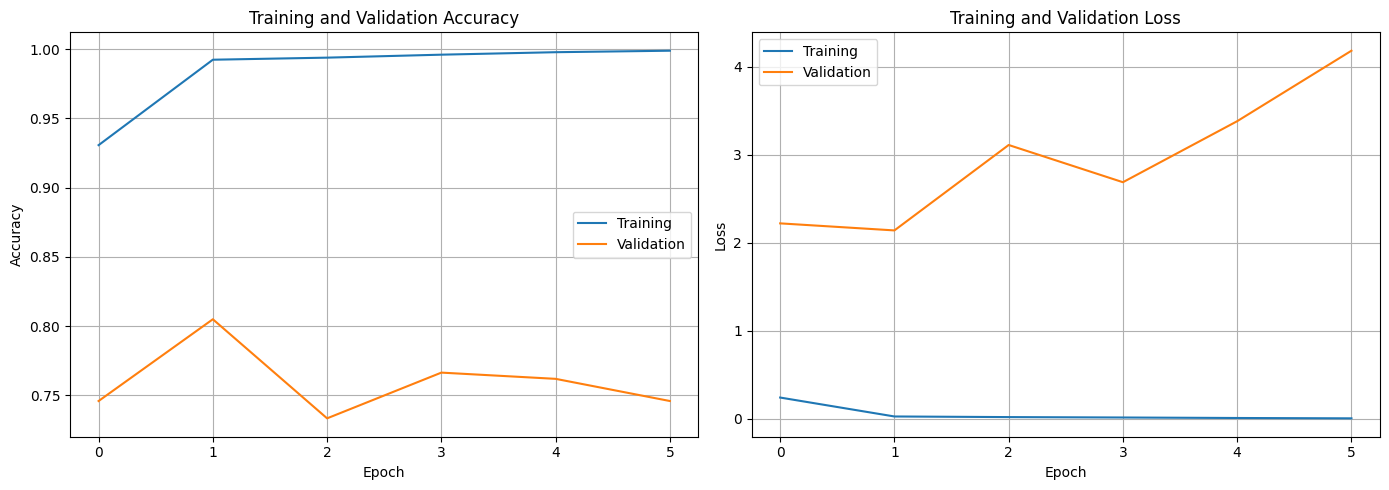

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.6965 - loss: 3.1406
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step

Test loss: 3.1406
Test accuracy: 69.65%

Classification Report:
               precision    recall  f1-score   support

      01_palm       0.46      0.77      0.58       400
         02_l       0.98      0.78      0.87       400
      03_fist       0.85      0.12      0.20       400
04_fist_moved       0.46      0.51      0.49       400
     05_thumb       0.92      0.32      0.47       400
     06_index       0.78      1.00      0.88       400
        07_ok       0.61      0.68      0.65       400
08_palm_moved       0.71      0.79      0.75       400
         09_c       0.94      1.00      0.97       400
      10_down       0.71      1.00      0.83       400

     accuracy                           0.70      4000
    macro avg       0.74      0.70      0.67      4000
 weighted avg       0.74      0.70      0.67      4000



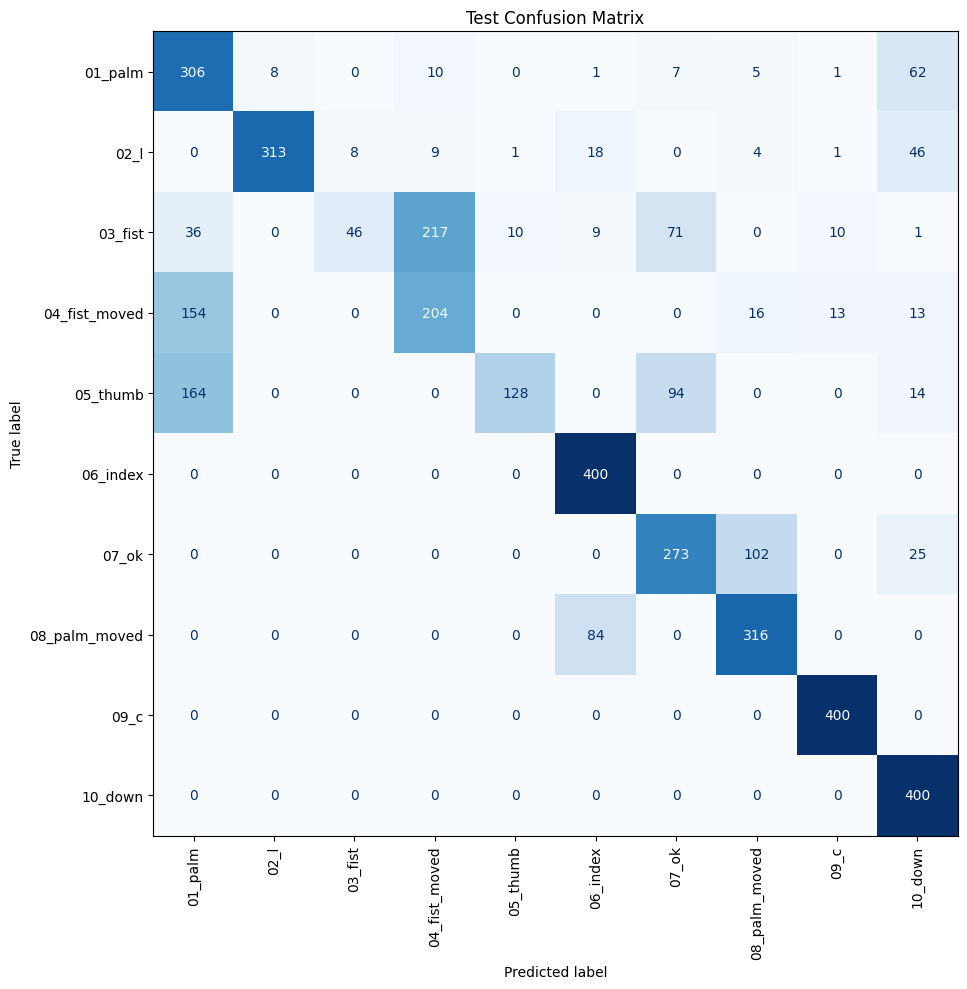

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

model = tf.keras.models.load_model(BEST_MODEL_PATH)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)

plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
print("Final training accuracy:",
      f"{history.history['accuracy'][-1] * 100:.2f}%")

print("Final validation accuracy:",
      f"{history.history['val_accuracy'][-1] * 100:.2f}%")

print("Best validation accuracy:",
      f"{max(history.history['val_accuracy']) * 100:.2f}%")

print("Minimum validation loss:",
      f"{min(history.history['val_loss']):.4f}")

print("Test accuracy:",
      f"{test_accuracy * 100:.2f}%")

print("Test loss:",
      f"{test_loss:.4f}")

Final training accuracy: 99.88%
Final validation accuracy: 74.60%
Best validation accuracy: 80.50%
Minimum validation loss: 2.1394
Test accuracy: 69.65%
Test loss: 3.1406


In [ ]:
import json
import os
import tensorflow as tf

model = tf.keras.models.load_model(BEST_MODEL_PATH)

FINAL_MODEL_PATH = "/content/hand_gesture_model.keras"
LABELS_PATH = "/content/class_names.json"

model.save(FINAL_MODEL_PATH)

with open(LABELS_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

print("Model saved successfully!")
print("Model path:", FINAL_MODEL_PATH)
print("Labels path:", LABELS_PATH)

Model saved successfully!
Model path: /content/hand_gesture_model.keras
Labels path: /content/class_names.json


125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.6965 - loss: 3.1406
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step

Test images: 4000
Test accuracy: 69.65%
Test loss: 3.1406

Classification report:
               precision    recall  f1-score   support

      01_palm       0.46      0.77      0.58       400
         02_l       0.98      0.78      0.87       400
      03_fist       0.85      0.12      0.20       400
04_fist_moved       0.46      0.51      0.49       400
     05_thumb       0.92      0.32      0.47       400
     06_index       0.78      1.00      0.88       400
        07_ok       0.61      0.68      0.65       400
08_palm_moved       0.71      0.79      0.75       400
         09_c       0.94      1.00      0.97       400
      10_down       0.71      1.00      0.83       400

     accuracy                           0.70      4000
    macro avg       0.74      0.70      0.67      4000
 weighted avg       0.74      0.70      0.67      4000



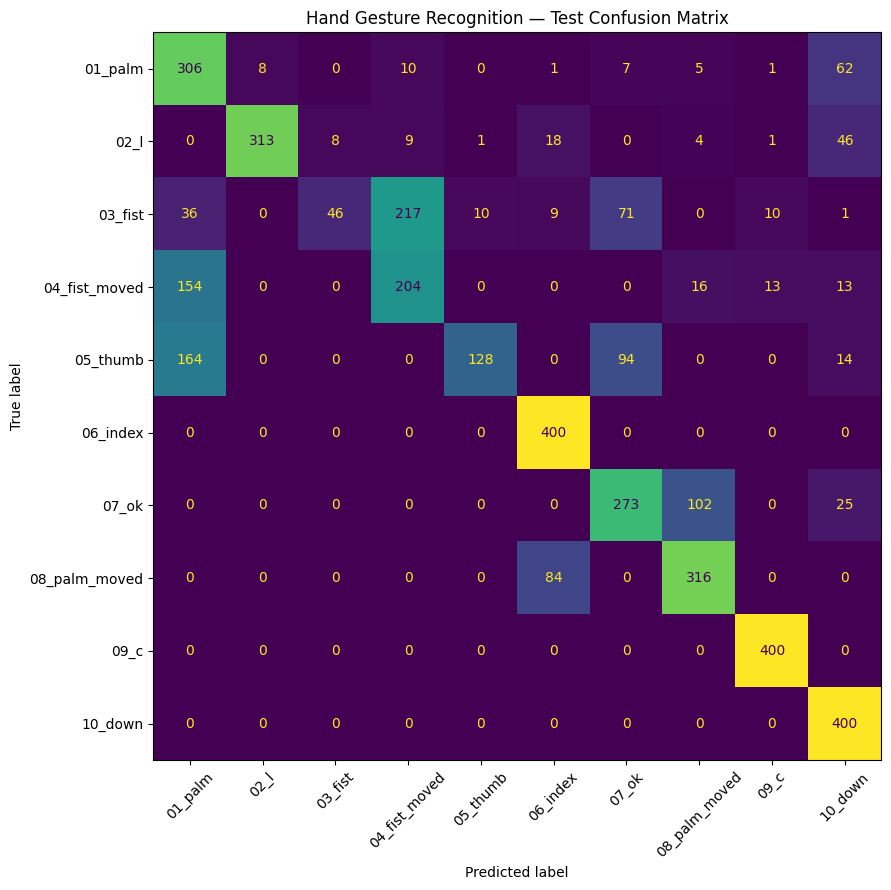


Saved evaluation artifacts in: /content/hand_gesture_output


In [ ]:
import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

MODEL_DIR = "/content/hand_gesture_output"
os.makedirs(MODEL_DIR, exist_ok=True)

# Correct paths: these files were exported directly to /content/
MODEL_PATH = "/content/hand_gesture_model.keras"
LABELS_PATH = "/content/class_names.json"
DATA_DIR = "/content/data/leapGestRecog"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Load the exact exported model and its label order
model = tf.keras.models.load_model(MODEL_PATH)

with open(LABELS_PATH, "r") as f:
    class_names = json.load(f)

# Build a test set using subjects 08 and 09 only
test_paths, y_true = [], []

for subject in ["08", "09"]:
    for label, class_name in enumerate(class_names):
        folder = os.path.join(DATA_DIR, subject, class_name)

        for filename in sorted(os.listdir(folder)):
            if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                test_paths.append(os.path.join(folder, filename))
                y_true.append(label)

y_true = np.asarray(y_true, dtype=np.int64)

assert len(test_paths) == 4000, (
    f"Expected 4000 test images, found {len(test_paths)}"
)
assert model.output_shape[-1] == len(class_names) == 10

def load_test_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=1, expand_animations=False
    )
    image.set_shape([None, None, 1])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

test_ds_final = tf.data.Dataset.from_tensor_slices(
    (test_paths, y_true)
)
test_ds_final = (
    test_ds_final
    .map(load_test_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Evaluate the saved model
test_loss, _ = model.evaluate(test_ds_final, verbose=1)

y_prob = model.predict(test_ds_final, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

test_accuracy = accuracy_score(y_true, y_pred)
print(f"\nTest images: {len(y_true)}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

# Classification report
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

pd.DataFrame(report).transpose().to_csv(
    os.path.join(MODEL_DIR, "classification_report.csv")
)

# Confusion matrix
cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title("Hand Gesture Recognition — Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    os.path.join(MODEL_DIR, "confusion_matrix.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Save a compact summary of the final evaluation
with open(os.path.join(MODEL_DIR, "evaluation_summary.json"), "w") as f:
    json.dump({
        "model": "hand_gesture_model.keras",
        "test_subjects": ["08", "09"],
        "test_images": len(y_true),
        "test_accuracy": float(test_accuracy),
        "test_loss": float(test_loss)
    }, f, indent=2)

print("\nSaved evaluation artifacts in:", MODEL_DIR)

In [ ]:
import json

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "hand_gesture_model.keras"
)

LABELS_PATH = os.path.join(
    MODEL_DIR,
    "class_names.json"
)

model.save(FINAL_MODEL_PATH)

with open(LABELS_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

print("Saved model:", FINAL_MODEL_PATH)
print("Saved labels:", LABELS_PATH)

Saved model: /content/hand_gesture_output/hand_gesture_model.keras
Saved labels: /content/hand_gesture_output/class_names.json


In [ ]:
import os

print("Improved model checkpoint exists:",
      os.path.exists(
          "/content/hand_gesture_output/best_hand_gesture_model_v2.keras"
      ))

print("Original model checkpoint exists:",
      os.path.exists(
          "/content/hand_gesture_output/best_hand_gesture_model.keras"
      ))

Improved model checkpoint exists: False
Original model checkpoint exists: True


In [ ]:
print("Training accuracy:",
      round(history.history["accuracy"][-1] * 100, 2), "%")

print("Best validation accuracy:",
      round(max(history.history["val_accuracy"]) * 100, 2), "%")

print("Minimum validation loss:",
      round(min(history.history["val_loss"]), 4))

Training accuracy: 99.88 %
Best validation accuracy: 80.5 %
Minimum validation loss: 2.1394


In [ ]:

import tensorflow as tf
import os
from tensorflow.keras import layers, models, callbacks, regularizers

IMG_HEIGHT = 128
IMG_WIDTH = 128
NUM_CLASSES = len(class_names)

tf.keras.utils.set_random_seed(42)

model_v2 = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1)),
    layers.Rescaling(1.0 / 255),

    # Data augmentation
    layers.RandomRotation(0.04),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.08),

    # CNN block 1
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.15),

    # CNN block 2
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.20),

    # CNN block 3
    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    # Smaller classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.40),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 128, 128, 1)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             

 Total params: 111,146 (434.16 KB)

 Trainable params: 110,698 (432.41 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:

MODEL_DIR = "/content/hand_gesture_output"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH_V2 = os.path.join(
    MODEL_DIR,
    "best_hand_gesture_model_v2.keras"
)

callbacks_v2 = [
    callbacks.ModelCheckpoint(
        BEST_MODEL_PATH_V2,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_v2
)


Epoch 1/20
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.2714 - loss: 2.1357
Epoch 1: val_loss improved from None to 3.98195, saving model to /content/hand_gesture_output/best_hand_gesture_model_v2.keras

Epoch 1: finished saving model to /content/hand_gesture_output/best_hand_gesture_model_v2.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 32s 57ms/step - accuracy: 0.4121 - loss: 1.8045 - val_accuracy: 0.1000 - val_loss: 3.9819 - learning_rate: 5.0000e-04
Epoch 2/20
437/438 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.7139 - loss: 1.0084
Epoch 2: val_loss improved from 3.98195 to 0.70728, saving model to /content/hand_gesture_output/best_hand_gesture_model_v2.keras

Epoch 2: finished saving model to /content/hand_gesture_output/best_hand_gesture_model_v2.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 36s 55ms/step - accuracy: 0.7575 - loss: 0.8695 - val_accuracy: 0.8225 - val_loss: 0.7073 - learning_rate: 5.0000e-04
Epoch 3/20
437/438 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8671 - loss: 0

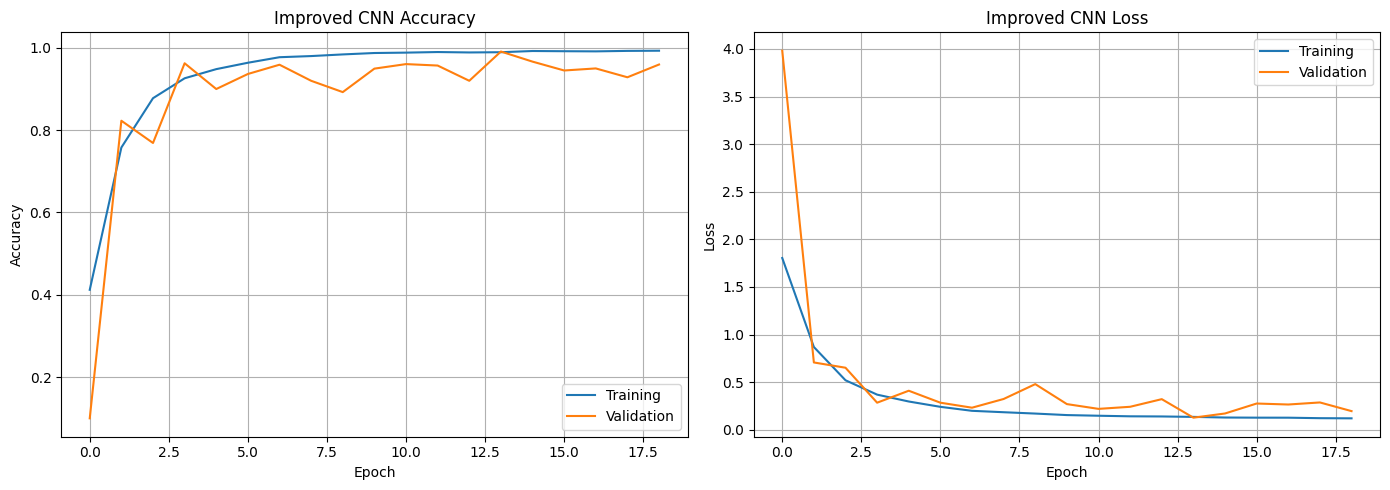

Best validation accuracy: 99.05%
Minimum validation loss: 0.1273


In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_v2.history["accuracy"], label="Training")
axes[0].plot(history_v2.history["val_accuracy"], label="Validation")
axes[0].set_title("Improved CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_v2.history["loss"], label="Training")
axes[1].plot(history_v2.history["val_loss"], label="Validation")
axes[1].set_title("Improved CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Best validation accuracy: "
      f"{max(history_v2.history['val_accuracy']) * 100:.2f}%")
print(f"Minimum validation loss: "
      f"{min(history_v2.history['val_loss']):.4f}")


125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.9170 - loss: 0.3167
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step
Test loss: 0.3167
Test accuracy: 91.70%
               precision    recall  f1-score   support

      01_palm       0.88      0.94      0.91       400
         02_l       0.81      0.89      0.85       400
      03_fist       1.00      0.55      0.71       400
04_fist_moved       0.87      0.99      0.93       400
     05_thumb       0.84      1.00      0.91       400
     06_index       1.00      0.80      0.89       400
        07_ok       0.96      1.00      0.98       400
08_palm_moved       0.99      1.00      0.99       400
         09_c       0.96      1.00      0.98       400
      10_down       0.96      0.99      0.98       400

     accuracy                           0.92      4000
    macro avg       0.93      0.92      0.91      4000
 weighted avg       0.93      0.92      0.91      4000



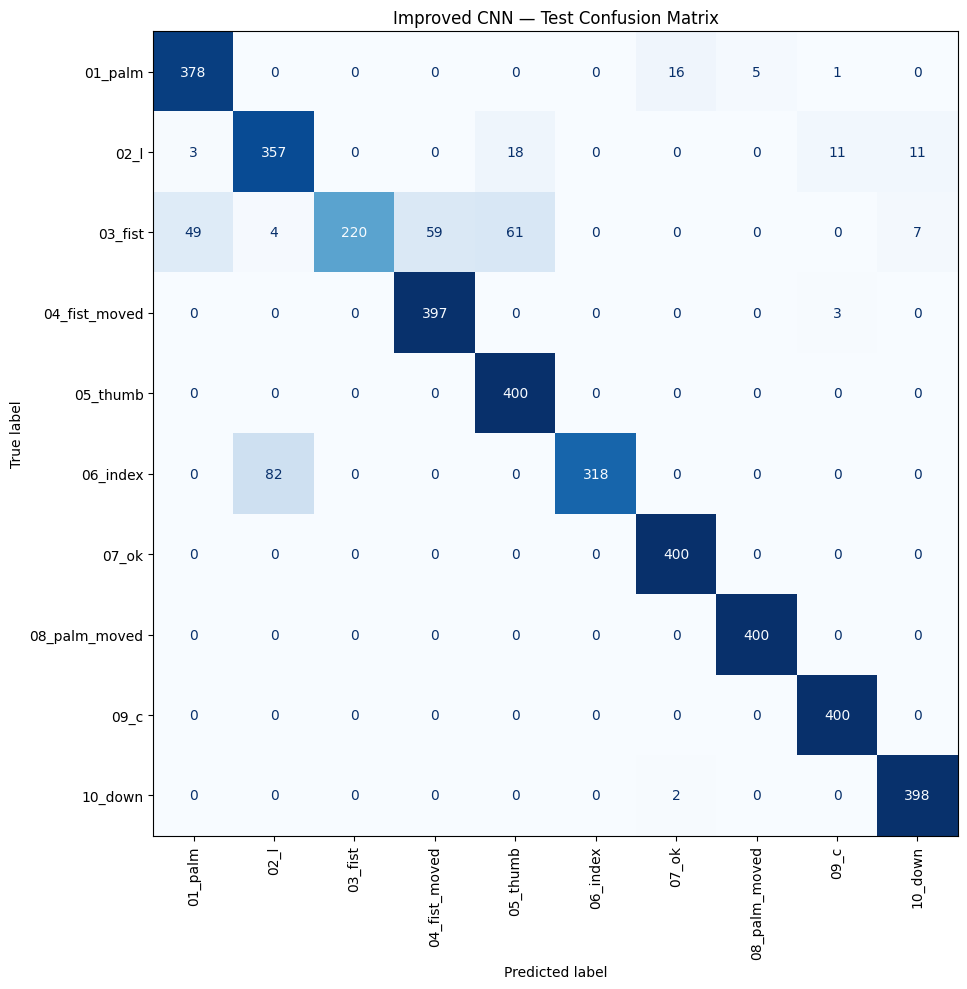

In [ ]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

best_model_v2 = tf.keras.models.load_model(BEST_MODEL_PATH_V2)

test_loss_v2, test_accuracy_v2 = best_model_v2.evaluate(
    test_ds, verbose=1
)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = best_model_v2.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"Test loss: {test_loss_v2:.4f}")
print(f"Test accuracy: {test_accuracy_v2 * 100:.2f}%")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred, labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues")

plt.title("Improved CNN — Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
import os
import json
import tensorflow as tf

MODEL_DIR = "/content/hand_gesture_output"

BEST_MODEL_PATH_V2 = os.path.join(
    MODEL_DIR, "best_hand_gesture_model_v2.keras"
)

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR, "hand_gesture_model.keras"
)

LABELS_PATH = os.path.join(
    MODEL_DIR, "class_names.json"
)

if not os.path.exists(BEST_MODEL_PATH_V2):
    raise FileNotFoundError(
        f"Checkpoint not found: {BEST_MODEL_PATH_V2}"
    )

# Load the best saved improved model
best_model_v2 = tf.keras.models.load_model(
    BEST_MODEL_PATH_V2
)

# Export the improved model
best_model_v2.save(FINAL_MODEL_PATH)

# Save class labels in the same order used during training
with open(LABELS_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

print("Improved model saved:", os.path.exists(FINAL_MODEL_PATH))
print("Class labels saved:", os.path.exists(LABELS_PATH))
print("Model path:", FINAL_MODEL_PATH)
print("Labels path:", LABELS_PATH)

Improved model saved: True
Class labels saved: True
Model path: /content/hand_gesture_output/hand_gesture_model.keras
Labels path: /content/hand_gesture_output/class_names.json


In [ ]:
import os
import json
import numpy as np
import tensorflow as tf

output_dir = "/content/hand_gesture_output"
model_path = os.path.join(output_dir, "hand_gesture_model.keras")
labels_path = os.path.join(output_dir, "class_names.json")

# Check that both files exist
assert os.path.exists(model_path), "Model file not found!"
assert os.path.exists(labels_path), "Class labels file not found!"

# Load the saved model and labels
model = tf.keras.models.load_model(model_path)

with open(labels_path, "r") as f:
    class_names = json.load(f)

print("Model loaded successfully!")
print("Number of classes:", len(class_names))
print("Model input shape:", model.input_shape)

# Test prediction using a sample input
sample = np.zeros((1, 128, 128, 1), dtype=np.float32)
prediction = model.predict(sample, verbose=0)

predicted_index = int(np.argmax(prediction[0]))

print("Prediction pipeline works!")
print("Predicted class:", class_names[predicted_index])
print("Output shape:", prediction.shape)

Model loaded successfully!
Number of classes: 10
Model input shape: (None, 128, 128, 1)
Prediction pipeline works!
Predicted class: 04_fist_moved
Output shape: (1, 10)


In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report

TEST_DIR = "/content/data/leapGestRecog"
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Use the test subjects: 08 and 09
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="int",
    color_mode="grayscale",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    validation_split=None
)

Found 20000 files belonging to 10 classes.


In [ ]:
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Saved model test accuracy:",
      f"{accuracy_score(y_true, y_pred):.2%}")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step
Saved model test accuracy: 10.06%
               precision    recall  f1-score   support

      01_palm       0.10      0.10      0.10      2000
         02_l       0.10      0.10      0.10      2000
      03_fist       0.11      0.10      0.10      2000
04_fist_moved       0.10      0.10      0.10      2000
     05_thumb       0.10      0.10      0.10      2000
     06_index       0.10      0.10      0.10      2000
        07_ok       0.10      0.10      0.10      2000
08_palm_moved       0.10      0.10      0.10      2000
         09_c       0.11      0.11      0.11      2000
      10_down       0.10      0.10      0.10      2000

     accuracy                           0.10     20000
    macro avg       0.10      0.10      0.10     20000
 weighted avg       0.10      0.10      0.10     20000



In [48]:
from google.colab import files

files.download(
    "/content/hand_gesture_output/hand_gesture_model.keras"
)

files.download(
    "/content/hand_gesture_output/class_names.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
import numpy as np
import tensorflow as tf
import os

MODEL_PATH = "/content/hand_gesture_output/hand_gesture_model.keras"
LABELS_PATH = "/content/hand_gesture_output/class_names.json"

# Load the saved model
model = tf.keras.models.load_model(MODEL_PATH)

# Load class labels
with open(LABELS_PATH, "r") as f:
    class_names = json.load(f)

print("Model loaded:", os.path.exists(MODEL_PATH))
print("Model output shape:", model.output_shape)
print("Number of class labels:", len(class_names))
print("Class labels:", class_names)

# Check whether the model produces valid probabilities
sample = np.random.randint(
    0, 256, size=(1, 128, 128, 1)
).astype("float32")

pred = model.predict(sample, verbose=0)

print("Prediction shape:", pred.shape)
print("Probability sum:", float(pred[0].sum()))
print("Predicted index:", int(np.argmax(pred[0])))

Model loaded: True
Model output shape: (None, 10)
Number of class labels: 10
Class labels: ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
Prediction shape: (1, 10)
Probability sum: 1.0
Predicted index: 8


In [ ]:
# Display likely dataset variables
for name in ["train_ds", "val_ds", "test_ds",
             "train_dataset", "val_dataset", "test_dataset",
             "class_names"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")
        if name.endswith("_ds") or name.endswith("_dataset"):
            print("  Cardinality:",
                  tf.data.experimental.cardinality(obj).numpy())

train_ds: _PrefetchDataset
  Cardinality: 438
val_ds: _PrefetchDataset
  Cardinality: 63
test_ds: _PrefetchDataset
  Cardinality: 625
class_names: list


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Predict using the saved model
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Number of test images:", len(y_true))
print("Number of predictions:", len(y_pred))
print("Class names:", class_names)

print("\nSaved model accuracy on test_ds:",
      f"{accuracy_score(y_true, y_pred):.2%}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

625/625 ━━━━━━━━━━━━━━━━━━━━ 28s 44ms/step
Number of test images: 20000
Number of predictions: 20000
Class names: ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']

Saved model accuracy on test_ds: 10.06%

Classification Report:
               precision    recall  f1-score   support

      01_palm       0.10      0.10      0.10      2000
         02_l       0.10      0.10      0.10      2000
      03_fist       0.11      0.10      0.10      2000
04_fist_moved       0.10      0.10      0.10      2000
     05_thumb       0.10      0.10      0.10      2000
     06_index       0.10      0.10      0.10      2000
        07_ok       0.10      0.10      0.10      2000
08_palm_moved       0.10      0.10      0.10      2000
         09_c       0.11      0.11      0.11      2000
      10_down       0.10      0.10      0.10      2000

     accuracy                           0.10     20000
    macro avg       0.10      0.10      0.

In [ ]:
import os

DATA_DIR = "/content/data/leapGestRecog"

print("Dataset folder exists:", os.path.exists(DATA_DIR))
print("\nTop-level folders:")

for folder in sorted(os.listdir(DATA_DIR))[:15]:
    path = os.path.join(DATA_DIR, folder)
    if os.path.isdir(path):
        subfolders = sorted(os.listdir(path))
        print(f"{folder}/ -> {subfolders[:5]}")

Dataset folder exists: True

Top-level folders:
00/ -> ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb']
01/ -> ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb']
02/ -> ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb']
03/ -> ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb']
04/ -> ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb']
05/ -> ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb']
06/ -> ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb']
07/ -> ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb']
08/ -> ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb']
09/ -> ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb']


In [ ]:
import os
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report

DATA_DIR = "/content/data/leapGestRecog"
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

test_images = []
test_labels = []

# Use only subjects 08 and 09
for subject in ["08", "09"]:
    subject_path = os.path.join(DATA_DIR, subject)

    for class_index, class_name in enumerate(class_names):
        class_path = os.path.join(subject_path, class_name)

        for filename in sorted(os.listdir(class_path)):
            if filename.lower().endswith((".png", ".jpg", ".jpeg")):
                test_images.append(os.path.join(class_path, filename))
                test_labels.append(class_index)

print("Test images found:", len(test_images))
print("Expected:", 4000)

# Load and preprocess the images
def load_image(path):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=1, expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image

test_ds_correct = tf.data.Dataset.from_tensor_slices(
    (test_images, test_labels)
)

test_ds_correct = test_ds_correct.map(
    lambda path, label: (load_image(path), label),
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Test images found: 4000
Expected: 4000


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Predict on the correct 4,000 test images
y_true = np.array(test_labels)
y_prob = model.predict(test_ds_correct, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_true, y_pred)

print("\nTest images:", len(y_true))
print("Final test accuracy:", f"{accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step

Test images: 4000
Final test accuracy: 91.70%

Classification Report:
               precision    recall  f1-score   support

      01_palm       0.88      0.94      0.91       400
         02_l       0.81      0.89      0.85       400
      03_fist       1.00      0.55      0.71       400
04_fist_moved       0.87      0.99      0.93       400
     05_thumb       0.84      1.00      0.91       400
     06_index       1.00      0.80      0.89       400
        07_ok       0.96      1.00      0.98       400
08_palm_moved       0.99      1.00      0.99       400
         09_c       0.96      1.00      0.98       400
      10_down       0.96      0.99      0.98       400

     accuracy                           0.92      4000
    macro avg       0.93      0.92      0.91      4000
 weighted avg       0.93      0.92      0.91      4000



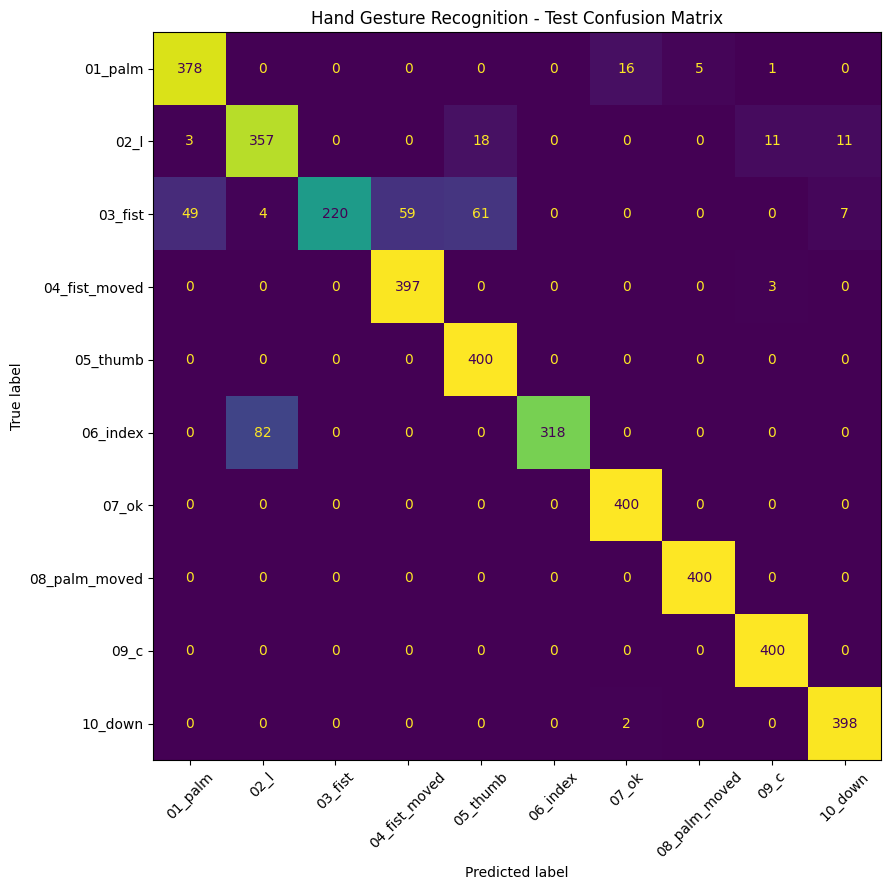

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(11, 9))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("Hand Gesture Recognition - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "/content/hand_gesture_output/confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step
Test images: 4000
Final test accuracy: 91.70%

Classification Report:
               precision    recall  f1-score   support

      01_palm       0.88      0.94      0.91       400
         02_l       0.81      0.89      0.85       400
      03_fist       1.00      0.55      0.71       400
04_fist_moved       0.87      0.99      0.93       400
     05_thumb       0.84      1.00      0.91       400
     06_index       1.00      0.80      0.89       400
        07_ok       0.96      1.00      0.98       400
08_palm_moved       0.99      1.00      0.99       400
         09_c       0.96      1.00      0.98       400
      10_down       0.96      0.99      0.98       400

     accuracy                           0.92      4000
    macro avg       0.93      0.92      0.91      4000
 weighted avg       0.93      0.92      0.91      4000



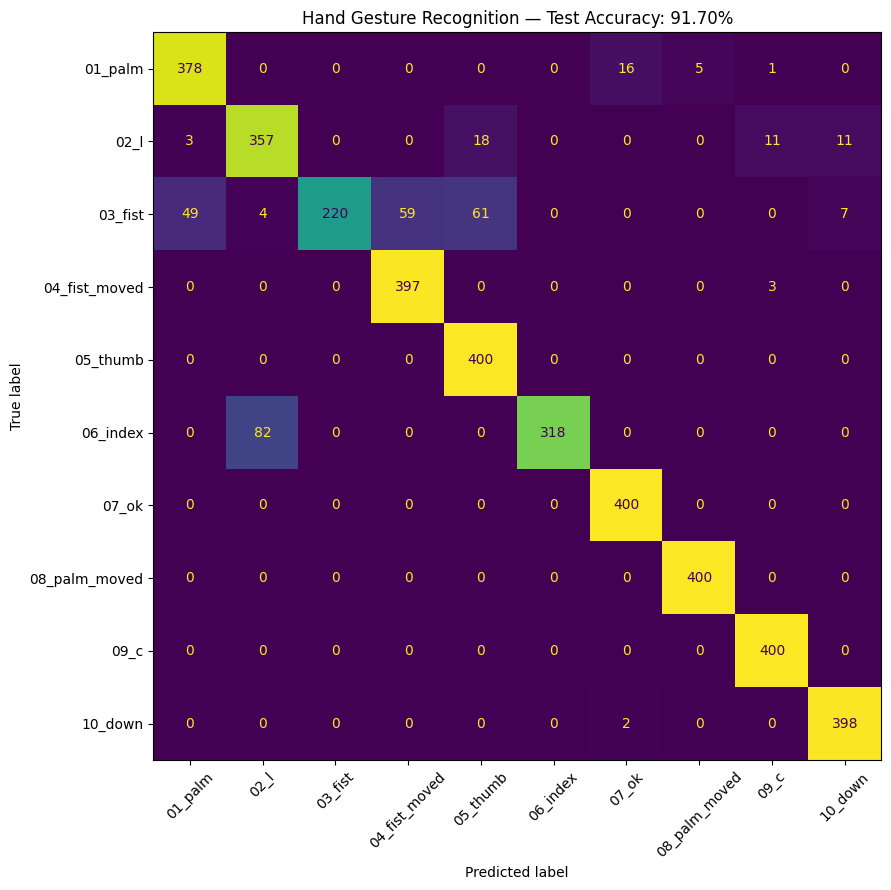

Saved classification report, confusion matrix PNG and CSV.


In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

OUTPUT_DIR = "/content/hand_gesture_output"
MODEL_PATH = os.path.join(OUTPUT_DIR, "hand_gesture_model.keras")

# Load the final improved model
model = tf.keras.models.load_model(MODEL_PATH)

# Use the explicitly prepared test set: subjects 08 and 09
y_true = np.array(test_labels)
y_prob = model.predict(test_ds_correct, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

test_accuracy = accuracy_score(y_true, y_pred)
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

print(f"Test images: {len(y_true)}")
print(f"Final test accuracy: {test_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

# Save classification report
with open(os.path.join(OUTPUT_DIR, "classification_report.json"), "w") as f:
    json.dump(report, f, indent=2)

# Generate and save confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title(f"Hand Gesture Recognition — Test Accuracy: {test_accuracy:.2%}")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Save raw confusion matrix
np.savetxt(
    os.path.join(OUTPUT_DIR, "confusion_matrix.csv"),
    cm,
    delimiter=",",
    fmt="%d"
)

print("Saved classification report, confusion matrix PNG and CSV.")

In [ ]:
from google.colab import files
from IPython.display import display
from PIL import Image
import io

uploaded = files.upload()

image_filename = next(iter(uploaded.keys()))
print("Uploaded image:", image_filename)

display(Image.open(io.BytesIO(uploaded[image_filename])))

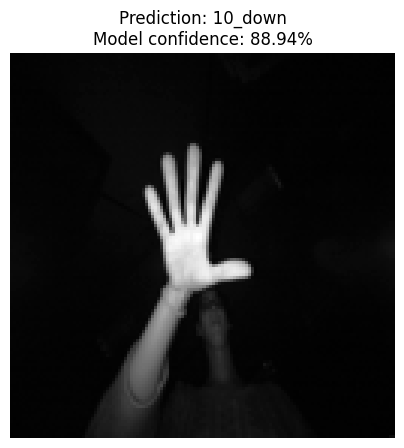

Predicted gesture: 10_down
Model confidence: 88.94%


In [51]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
import io
import os

OUTPUT_DIR = "/content/hand_gesture_output"
MODEL_PATH = os.path.join(OUTPUT_DIR, "hand_gesture_model.keras")

# Load the saved model
model = tf.keras.models.load_model(MODEL_PATH)

# Load class names in the same order used during training
with open(os.path.join(OUTPUT_DIR, "class_names.json"), "r") as f:
    class_names = json.load(f)

# Preprocess the uploaded image
img = Image.open(io.BytesIO(uploaded[image_filename]))
img = img.convert("L").resize((128, 128))

img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=(0, -1))

# Predict
predictions = model.predict(img_array, verbose=0)[0]
predicted_index = int(np.argmax(predictions))
predicted_class = class_names[predicted_index]
confidence = float(predictions[predicted_index]) * 100

# Display result
plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray")
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Model confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

print("Predicted gesture:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")

<IPython.core.display.Javascript object>

Captured webcam image:


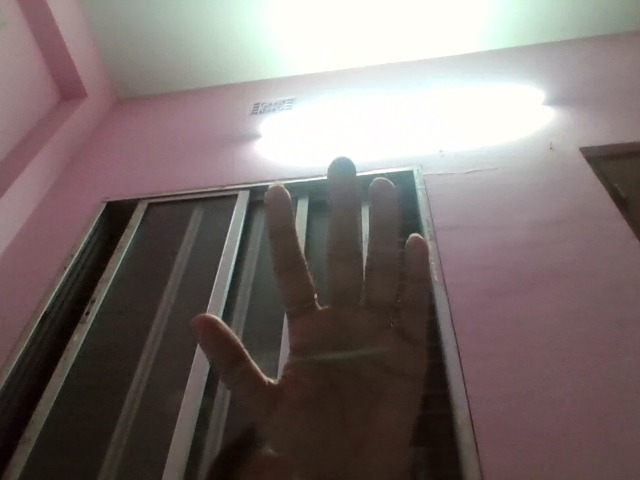

In [52]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
from base64 import b64decode
import cv2
import numpy as np

def capture_webcam_image():
    js = Javascript("""
    async function captureImage() {
        const div = document.createElement('div');
        const button = document.createElement('button');
        button.textContent = 'Capture hand image';
        div.appendChild(button);

        const video = document.createElement('video');
        video.style.display = 'block';
        video.width = 480;
        div.appendChild(video);
        document.body.appendChild(div);

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        await video.play();

        await new Promise(resolve => {
            button.onclick = resolve;
        });

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getTracks().forEach(track => track.stop());
        div.remove();

        return canvas.toDataURL('image/jpeg');
    }
    """)
    display(js)

    data = eval_js("captureImage()")
    image_bytes = b64decode(data.split(",")[1])

    return cv2.imdecode(
        np.frombuffer(image_bytes, np.uint8),
        cv2.IMREAD_COLOR
    )

frame = capture_webcam_image()

print("Captured webcam image:")
cv2_imshow(frame)

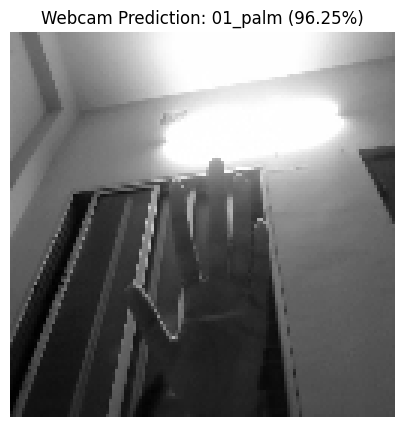

Predicted gesture: 01_palm
Model confidence: 96.25%


In [53]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Convert webcam image to grayscale and resize
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(gray, (128, 128))

img_array = resized.astype(np.float32)
img_array = np.expand_dims(img_array, axis=(0, -1))

# Predict gesture
predictions = model.predict(img_array, verbose=0)[0]
predicted_index = int(np.argmax(predictions))
predicted_class = class_names[predicted_index]
confidence = float(predictions[predicted_index]) * 100

plt.figure(figsize=(6, 5))
plt.imshow(resized, cmap="gray")
plt.title(f"Webcam Prediction: {predicted_class} ({confidence:.2f}%)")
plt.axis("off")
plt.show()

print("Predicted gesture:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")

In [54]:
import os

OUTPUT_DIR = "/content/hand_gesture_output"

for filename in os.listdir(OUTPUT_DIR):
    filepath = os.path.join(OUTPUT_DIR, filename)
    if os.path.isfile(filepath):
        print(filename, f"({os.path.getsize(filepath) / 1024:.1f} KB)")

classification_report.csv (0.7 KB)
confusion_matrix.png (152.9 KB)
class_names.json (0.1 KB)
best_hand_gesture_model_v2.keras (1382.4 KB)
classification_report.json (1.6 KB)
confusion_matrix.csv (0.2 KB)
evaluation_summary.json (0.2 KB)
best_hand_gesture_model.keras (50303.2 KB)
hand_gesture_model.keras (1381.5 KB)
